In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data (2).csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0         4.0
1  2018-01-04      1  address_0    product_1         4.0
2  2018-01-04      1  address_0    product_2         5.0
3  2018-01-04      1  address_0    product_3        10.0
4  2018-01-04      1  address_0    product_4         2.0


Проверяем формат столбцов

In [5]:
df.info

<bound method DataFrame.info of               Дата  Склад   Контрагент Номенклатура  Количество
0       2018-01-04      1    address_0    product_0         4.0
1       2018-01-04      1    address_0    product_1         4.0
2       2018-01-04      1    address_0    product_2         5.0
3       2018-01-04      1    address_0    product_3        10.0
4       2018-01-04      1    address_0    product_4         2.0
...            ...    ...          ...          ...         ...
138789  2018-04-25      4  address_134   product_13         1.0
138790  2018-04-25      4  address_134   product_14         1.0
138791  2018-04-25      4  address_134   product_17         1.0
138792  2018-04-25      4  address_135    product_0         2.0
138793  2018-04-25      4  address_135           pr         NaN

[138794 rows x 5 columns]>

Сразу переведем столбец "Дата" в правильный формат

In [6]:
df['Дата'] = pd.to_datetime(df['Дата'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138794 entries, 0 to 138793
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Дата          138794 non-null  datetime64[ns]
 1   Склад         138794 non-null  int64         
 2   Контрагент    138794 non-null  object        
 3   Номенклатура  138794 non-null  object        
 4   Количество    138793 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 5.3+ MB


Сгруппируйте данные по дате, посчитайте количество продаж

In [7]:
grouped_df = df.groupby('Дата')['Количество'].sum().reset_index()

Вывести несколько первых строк сгруппированных данных

In [8]:
display(grouped_df.head())

,Дата,Количество
0,2018-01-04,3734.0
1,2018-01-05,3643.0
2,2018-01-06,3193.0
3,2018-01-07,3298.0
4,2018-01-09,4055.0


Нарисуйте график продаж у `grouped_df`

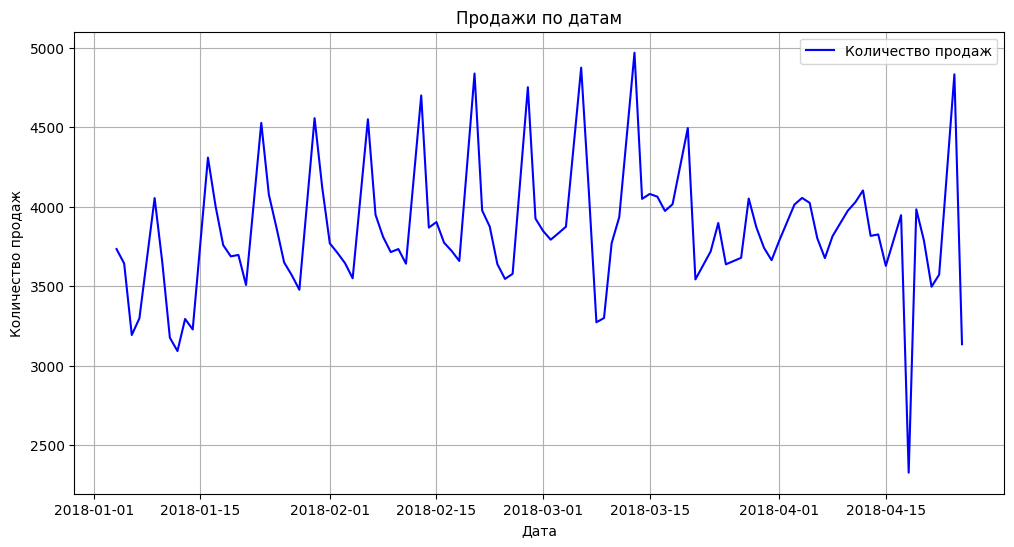

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(grouped_df['Дата'], grouped_df['Количество'], label='Количество продаж', color='blue')
plt.title('Продажи по датам')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')
plt.grid(True)
plt.legend()
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

1. Сезонность и периодичность:
  На графике отчетливо видна выраженная недельная цикличность с регулярными пиками и спадами.
  Пики продаж повторяются примерно раз в неделю.
2. Тренды:
  С начала января до середины марта наблюдается плавное повышение продаж где средний уровень продаж растет с 3500 до 4100.
  Во второй половине марта и в апреле продажи стабилизируются или слегка идут на спад.
3. Аномалии и выбросы:
  Самое сильное падение произошло во второй половине апреля, где объем продаж резко упал ниже 2500.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [14]:
max_outlier_row = df.loc[df['Количество'].idxmax()]
print("Строка с максимальным выбросом по количеству продаж в df:")
display(pd.DataFrame(max_outlier_row).T)

Строка с максимальным выбросом по количеству продаж в df:


,Дата,Склад,Контрагент,Номенклатура,Количество
94435,2018-03-18 00:00:00,5,address_194,product_1,45.0


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [15]:
available_months = df['Дата'].dt.month.unique()
print(f"Доступные месяцы в данных: {available_months} (1 - Январь, 4 - Апрель)")

df_warehouse3 = df[df['Склад'] == 3].copy()
df_warehouse3['День_недели'] = df_warehouse3['Дата'].dt.dayofweek

wed_df = df_warehouse3[df_warehouse3['День_недели'] == 2]

top_product = wed_df.groupby('Ноmenклатура')['Количество'].sum().reset_index() if 'Ноmenклатура' in wed_df.columns else wed_df.groupby('Номенклатура')['Количество'].sum().reset_index()
top_product = top_product.sort_values(by='Количество', ascending=False)

print("\nТоп-5 товаров по продажам по средам у 3 склада за весь доступный период (Январь-Апрель):")
display(top_product.head(5))

Доступные месяцы в данных: [1 2 3 4] (1 - Январь, 4 - Апрель)

Топ-5 товаров по продажам по средам у 3 склада за весь доступный период (Январь-Апрель):


,Номенклатура,Количество
1,product_1,2185.0
12,product_2,2142.0
0,product_0,1512.0
20,product_6,1344.0
17,product_3,929.0


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

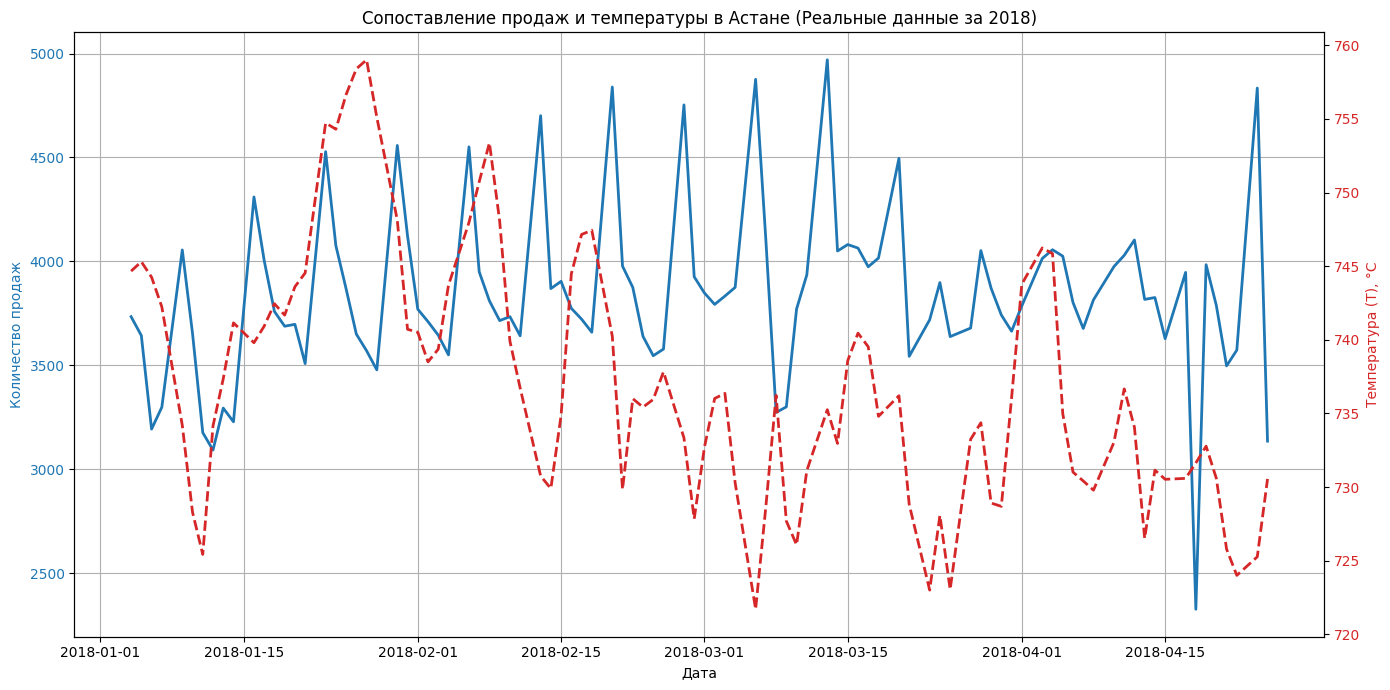

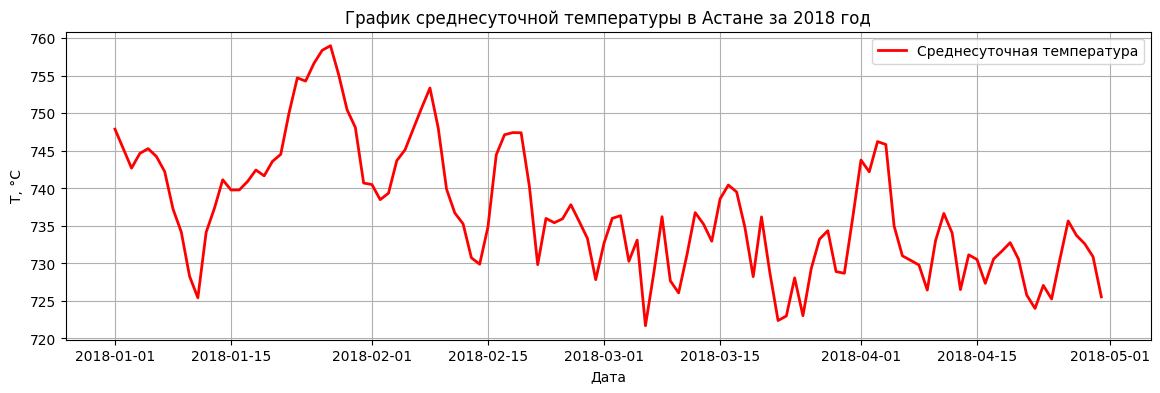

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    weather_raw = pd.read_csv('/content/35188.01.01.2018.30.04.2018.1.0.0.ru.ansi.00000000.csv.gz',
                              compression='gzip', sep=';', encoding='cp1251', comment='#', skiprows=6)
except Exception:
    weather_raw = pd.read_csv('/content/35188.01.01.2018.30.04.2018.1.0.0.ru.ansi.00000000.csv.gz',
                              compression='gzip', sep=';', encoding='cp1251')

weather_raw = weather_raw.reset_index()

time_col = [col for col in weather_raw.columns if 'время' in col.lower() or 'time' in col.lower() or 'index' in col.lower()][0]
temp_col = [col for col in weather_raw.columns if col.strip() == 'T' or col.strip() == 'T_air'][0]

weather_raw['Дата_время'] = pd.to_datetime(weather_raw[time_col], format='%d.%m.%Y %H:%M', errors='coerce')
weather_raw['Дата'] = weather_raw['Дата_время'].dt.normalize()
weather_raw['T'] = pd.to_numeric(weather_raw[temp_col], errors='coerce')

weather_daily = weather_raw.dropna(subset=['T', 'Дата']).groupby('Дата')['T'].mean().reset_index()

merged_df = pd.merge(grouped_df, weather_daily, on='Дата', how='inner')

fig, ax1 = plt.subplots(figsize=(14, 7))

color = 'tab:blue'
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж', color=color)
ax1.plot(merged_df['Дата'], merged_df['Количество'], color=color, label='Количество продаж', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Температура (T), °C', color=color)
ax2.plot(merged_df['Дата'], merged_df['T'], color=color, linestyle='--', label='Температура (T)', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Сопоставление продаж и температуры в Астане (Реальные данные за 2018)')
fig.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(weather_daily['Дата'], weather_daily['T'], color='red', label='Среднесуточная температура', linewidth=2)
plt.title('График среднесуточной температуры в Астане за 2018 год')
plt.xlabel('Дата')
plt.ylabel('T, °C')
plt.grid(True)
plt.legend()
plt.show()